In [6]:
!pip install osmnx geopandas matplotlib

In [7]:
import osmnx as ox
import geopandas as gpd
import matplotlib.pyplot as plt

print("OSMnx version:", ox.__version__)
print("Libraries imported successfully!")

OSMnx version: 2.1.1
Libraries imported successfully!


In [8]:
# Define our study area
place = "Tashkent, Uzbekistan"

# Select green space categories
tags = {
    "leisure": ["park", "garden", "nature_reserve"],
    "landuse": ["grass", "forest", "meadow", "recreation_ground"],
    "natural": ["wood", "grassland"]
}

# Download green spaces
green = ox.features_from_place(
    place,
    tags=tags
)

print("Number of features:", len(green))
print("Data downloaded successfully!")

Number of features: 6482
Data downloaded successfully!


In [9]:
green.head()

geometry  \
element  id                                                               
node     6034845189                            POINT (69.3479 41.28347)   
         6034854981                           POINT (69.34716 41.28334)   
         12133123408                          POINT (69.30331 41.32055)   
         13891164395                          POINT (69.28009 41.31195)   
relation 1252000      POLYGON ((69.22749 41.21999, 69.22765 41.21981...   

                     leisure                       name description  \
element  id                                                           
node     6034845189     park                Парк Ягодка         NaN   
         6034854981     park        Большой парк Ягодка         NaN   
         12133123408    park  парк Славянских Скульптур         NaN   
         13891164395    park                        NaN         NaN   
relation 1252000        park  Sergeli Markaziy Xiyoboni         NaN   

                     leaf_cycle leaf_type natural                name:en  \
element  id                                                                
node     6034845189         NaN       NaN     NaN                    NaN   
         6034854981         NaN       NaN     NaN                    NaN   
         12133123408        NaN       NaN     NaN  Slavic Sculpture Park   
         13891164395        NaN       NaN     NaN                    NaN   
relation 1252000            NaN       NaN     NaN   Sergeli Central Park   

                                       name:uz name:fa  ...  \
element  id                                             ...   
node     6034845189                        NaN     NaN  ...   
         6034854981                        NaN     NaN  ...   
         12133123408  Slavyan haykallari parki     NaN  ...   
         13891164395                       NaN     NaN  ...   
relation 1252000                           NaN     NaN  ...   

                     charge:conditional fee:conditional payment:cash  \
element  id                                                            
node     6034845189                 NaN             NaN          NaN   
         6034854981                 NaN             NaN          NaN   
         12133123408                NaN             NaN          NaN   
         13891164395                NaN             NaN          NaN   
relation 1252000                    NaN             NaN          NaN   

                     payment:debit_cards payment:wire_transfer          type  \
element  id                                                                    
node     6034845189                  NaN                   NaN           NaN   
         6034854981                  NaN                   NaN           NaN   
         12133123408                 NaN                   NaN           NaN   
         13891164395                 NaN                   NaN           NaN   
relation 1252000                     NaN                   NaN  multipolygon   

                     construction bicycle garden:type fixme  
element  id                                                  
node     6034845189           NaN     NaN         NaN   NaN  
         6034854981           NaN     NaN         NaN   NaN  
         12133123408          NaN     NaN         NaN   NaN  
         13891164395          NaN     NaN         NaN   NaN  
relation 1252000              NaN     NaN         NaN   NaN  

[5 rows x 67 columns]

In [10]:
print(green.geom_type.value_counts())
print(green.columns.tolist())

Polygon               6474
Point                    4
MultiPolygon             2
GeometryCollection       2
Name: count, dtype: int64
['geometry', 'leisure', 'name', 'description', 'leaf_cycle', 'leaf_type', 'natural', 'name:en', 'name:uz', 'name:fa', 'name:ru', 'old_name', 'old_name:ru', 'wikidata', 'wikipedia', 'start_date', 'barrier', 'fee', 'fence_type', 'garden:style', 'leisure_1', 'opening_hours', 'tourism', 'operator:wikidata', 'operator:wikipedia', 'addr:housenumber', 'phone', 'website', 'landuse', 'place', 'wikimedia_commons', 'amenity', 'ele', 'name:kaa', 'surface', 'source', 'layer', 'addr:place', 'vehicle', 'access', 'sport', 'dog', 'smoking', 'building', 'resort', 'addr:city', 'addr:postcode', 'addr:street', 'parking', 'alt_name:ru', 'alt_name', 'alt_name:en', 'old_name:en', 'area', 'traffic_calming', 'building:levels', 'charge', 'charge:conditional', 'fee:conditional', 'payment:cash', 'payment:debit_cards', 'payment:wire_transfer', 'type', 'construction', 'bicycle', 'gard

In [11]:
# Keep only polygon geometries
green_poly = green[
    green.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

# Remove empty geometries
green_poly = green_poly[
    ~green_poly.geometry.is_empty
]

print("Polygon features:", len(green_poly))
print("CRS:", green_poly.crs)

Polygon features: 6476
CRS: epsg:4326


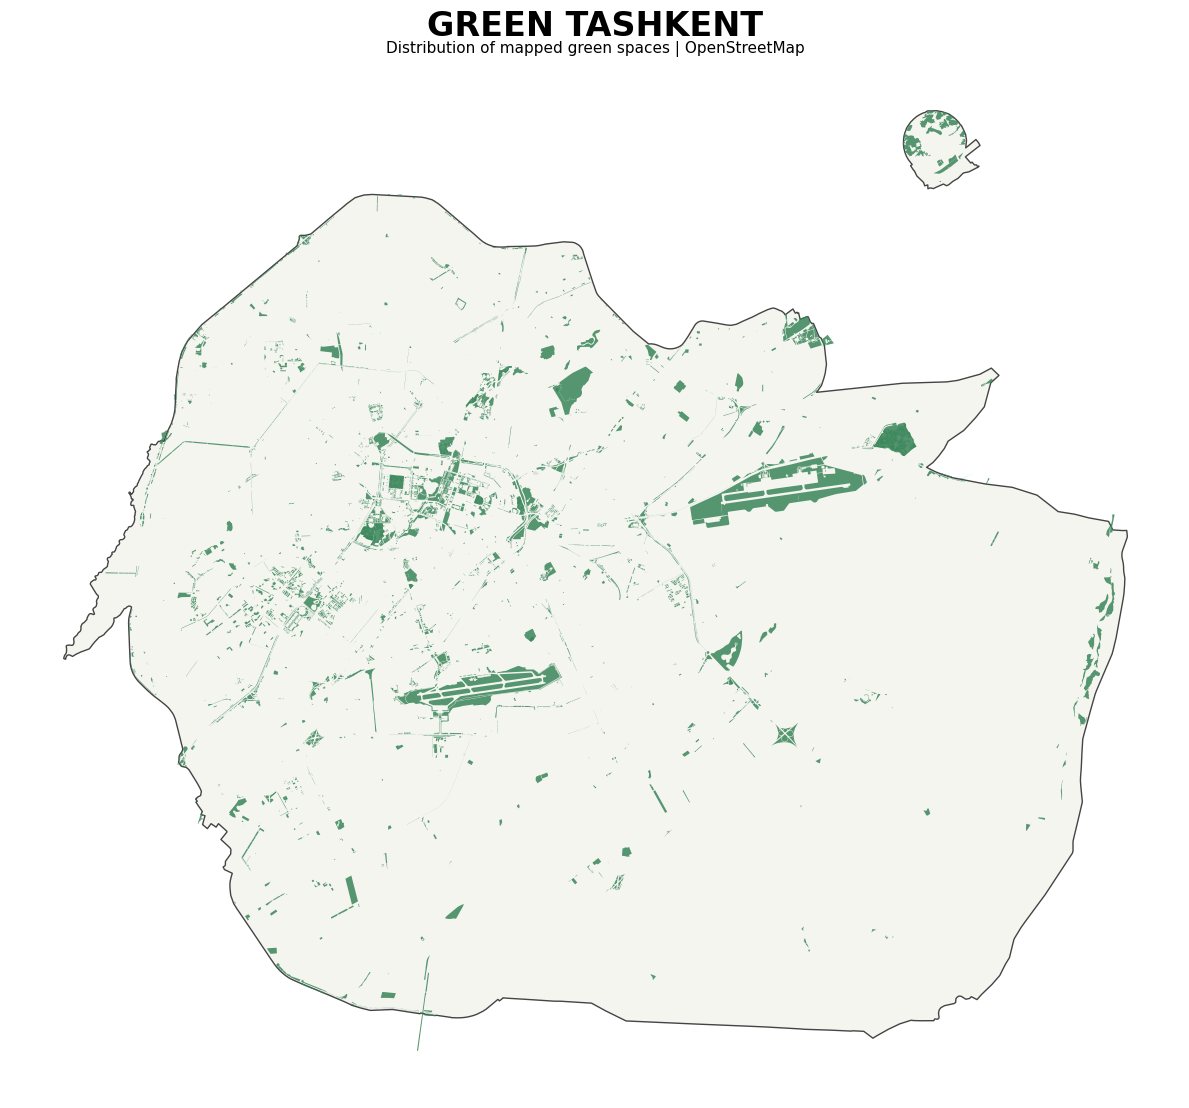

In [12]:
# Get Tashkent administrative boundary
boundary = ox.geocode_to_gdf("Tashkent, Uzbekistan")

# Convert both layers to a projected CRS
green_map = green_poly.to_crs(epsg=3857)
boundary_map = boundary.to_crs(epsg=3857)

# Create figure
fig, ax = plt.subplots(figsize=(12, 12))

# Plot city boundary
boundary_map.plot(
    ax=ax,
    color="#F5F5F0",
    edgecolor="#444444",
    linewidth=1
)

# Plot green spaces
green_map.plot(
    ax=ax,
    color="#39865A",
    edgecolor="none",
    alpha=0.85
)

# Title
ax.set_title(
    "GREEN TASHKENT",
    fontsize=24,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5, 1.01,
    "Distribution of mapped green spaces | OpenStreetMap",
    transform=ax.transAxes,
    ha="center",
    fontsize=11
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [13]:
# Select only parks, gardens and recreational areas
selected = green_poly[
    (
        green_poly["leisure"].isin(
            ["park", "garden", "nature_reserve"]
        )
    ) |
    (
        green_poly["landuse"].isin(
            ["recreation_ground"]
        )
    )
].copy()

# Project to metres
selected_map = selected.to_crs(epsg=3857)

# Remove very small polygons (less than 1,000 m²)
selected_map = selected_map[
    selected_map.geometry.area >= 1000
]

print("Selected green spaces:", len(selected_map))

Selected green spaces: 115


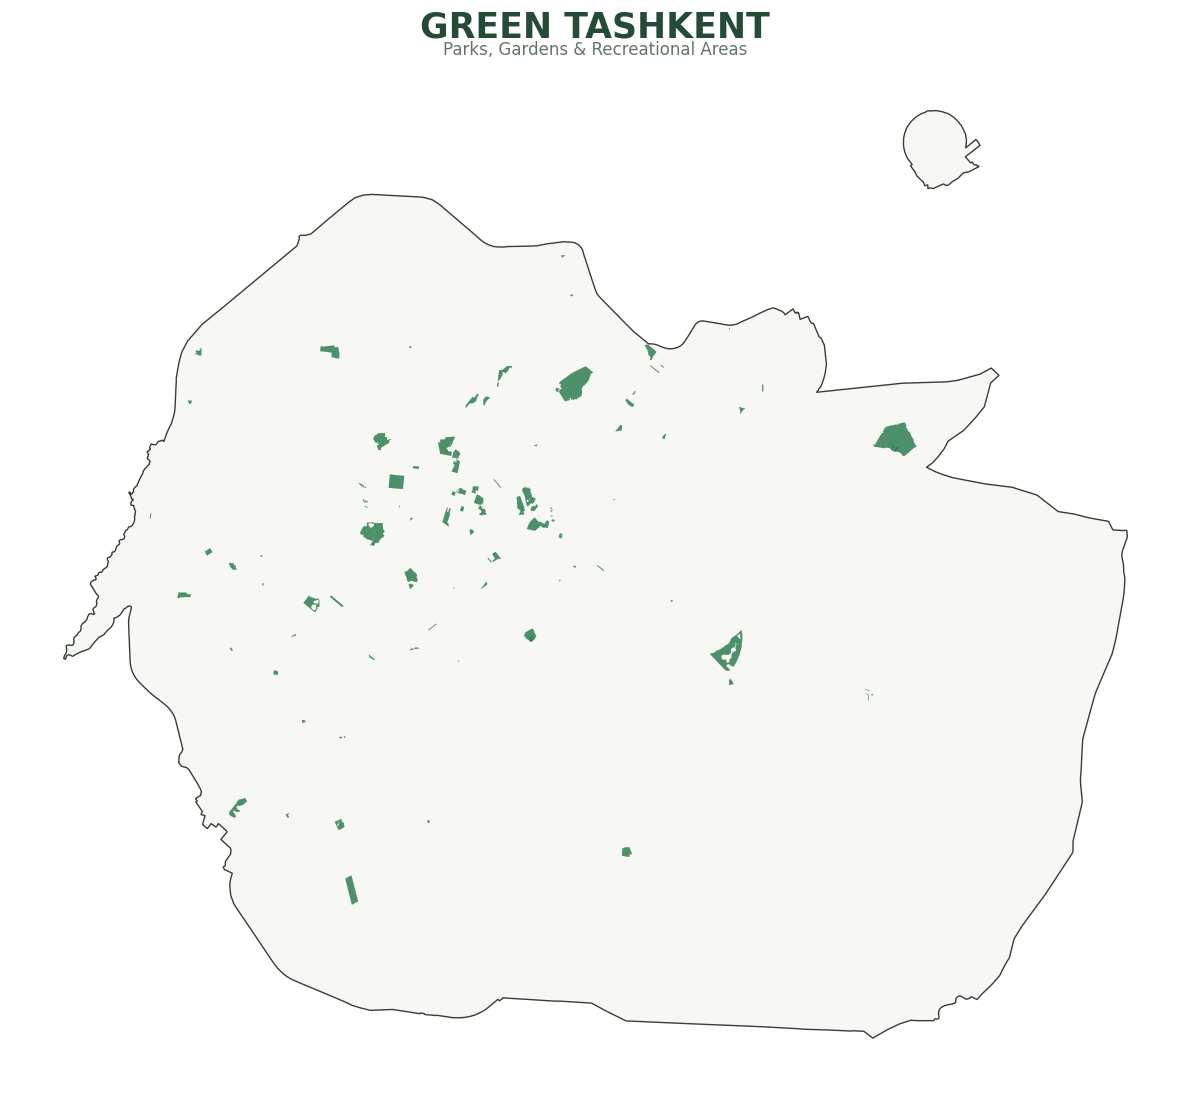

In [14]:
fig, ax = plt.subplots(figsize=(12, 12))

# Administrative boundary
boundary_map.plot(
    ax=ax,
    color="#F7F8F4",
    edgecolor="#343F38",
    linewidth=1
)

# Selected green spaces
selected_map.plot(
    ax=ax,
    color="#39865A",
    edgecolor="#246B45",
    linewidth=0.15,
    alpha=0.9
)

ax.set_title(
    "GREEN TASHKENT",
    fontsize=25,
    fontweight="bold",
    color="#244B35",
    pad=20
)

ax.text(
    0.5, 1.01,
    "Parks, Gardens & Recreational Areas",
    transform=ax.transAxes,
    ha="center",
    fontsize=12,
    color="#65736A"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

In [15]:
!pip install matplotlib-scalebar

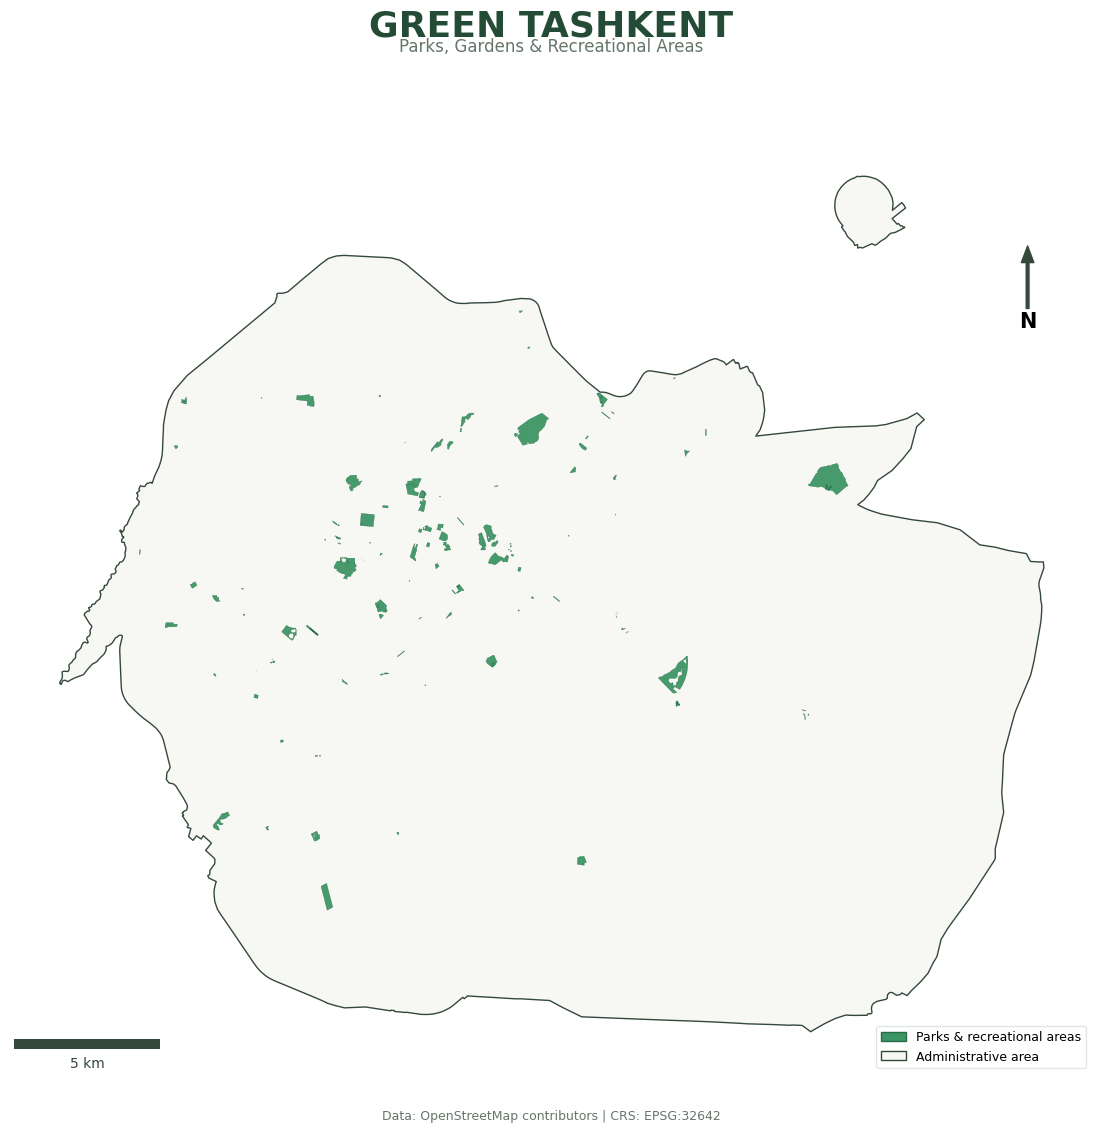

In [16]:
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.patches import Patch

# Use UTM Zone 42N for accurate distance measurements
green_final = selected.to_crs(epsg=32642)
boundary_final = boundary.to_crs(epsg=32642)

# Create figure
fig, ax = plt.subplots(figsize=(12, 12), facecolor="#FFFFFF")

# Plot administrative boundary
boundary_final.plot(
    ax=ax,
    color="#F7F8F4",
    edgecolor="#35483C",
    linewidth=1.0,
    zorder=1
)

# Plot parks and recreational areas
green_final.plot(
    ax=ax,
    color="#3C9565",
    edgecolor="#286B47",
    linewidth=0.25,
    alpha=0.95,
    zorder=2
)

# Title
fig.suptitle(
    "GREEN TASHKENT",
    fontsize=26,
    fontweight="bold",
    color="#244B35",
    y=0.96
)

fig.text(
    0.5, 0.925,
    "Parks, Gardens & Recreational Areas",
    ha="center",
    fontsize=12,
    color="#65766A"
)

# Legend
legend_elements = [
    Patch(
        facecolor="#3C9565",
        edgecolor="#286B47",
        label="Parks & recreational areas"
    ),
    Patch(
        facecolor="#F7F8F4",
        edgecolor="#35483C",
        label="Administrative area"
    )
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#D9E0DA",
    fontsize=9
)

# Scale bar
ax.add_artist(
    ScaleBar(
        1,
        units="m",
        dimension="si-length",
        location="lower left",
        box_alpha=0,
        color="#35483C",
        length_fraction=0.15
    )
)

# North arrow
ax.annotate(
    "N",
    xy=(0.94, 0.88),
    xytext=(0.94, 0.80),
    xycoords="axes fraction",
    textcoords="axes fraction",
    ha="center",
    va="center",
    fontsize=15,
    fontweight="bold",
    arrowprops=dict(
        facecolor="#35483C",
        edgecolor="#35483C",
        width=2,
        headwidth=9
    )
)

# Remove axes
ax.set_axis_off()

# Source and credits
fig.text(
    0.5, 0.035,
    "Data: OpenStreetMap contributors | CRS: EPSG:32642",
    ha="center",
    fontsize=9,
    color="#65766A"
)

plt.tight_layout(rect=[0.02, 0.06, 0.98, 0.91])

plt.savefig(
    "Day_07_Green_Tashkent.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [17]:
# Retrieve Yakkasaray administrative boundary
district = ox.geocode_to_gdf(
    "Yakkasaroy Tumani, Tashkent, Uzbekistan"
)

# Check the result
print("District:", district.iloc[0]["display_name"])
print("Geometry:", district.geometry.iloc[0].geom_type)
print("CRS:", district.crs)

# Reproject to UTM Zone 42N
district = district.to_crs(epsg=32642)

# Extract study area polygon
district_polygon = district.geometry.iloc[0]

District: Yakkasaray District, Tashkent, 100000, Uzbekistan
Geometry: Polygon
CRS: epsg:4326


In [18]:
# Convert district boundary back to WGS84 for OSM queries
district_wgs84 = district.to_crs(epsg=4326)
polygon = district_wgs84.geometry.iloc[0]

# 1. Building footprints
buildings = ox.features_from_polygon(
    polygon,
    tags={"building": True}
)

# 2. Green spaces
green_tags = {
    "leisure": ["park", "garden", "nature_reserve"],
    "landuse": ["recreation_ground"]
}

parks = ox.features_from_polygon(
    polygon,
    tags=green_tags
)

# 3. Road network
G = ox.graph_from_polygon(
    polygon,
    network_type="drive",
    simplify=True
)

roads = ox.graph_to_gdfs(
    G,
    nodes=False,
    edges=True
)

print("Buildings:", len(buildings))
print("Green spaces:", len(parks))
print("Road segments:", len(roads))

Buildings: 10137
Green spaces: 11
Road segments: 2284


In [19]:
# Reproject all datasets to UTM Zone 42N
buildings = buildings.to_crs(epsg=32642)
parks = parks.to_crs(epsg=32642)
roads = roads.to_crs(epsg=32642)

# Create district boundary GeoDataFrame
district_clip = district[["geometry"]].copy()

# Keep polygon geometries for buildings
buildings = buildings[
    buildings.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

# Keep polygon geometries for parks
parks = parks[
    parks.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

# Clip all layers to Yakkasaray
buildings_clip = gpd.clip(buildings, district_clip)
parks_clip = gpd.clip(parks, district_clip)
roads_clip = gpd.clip(roads, district_clip)

print("Clipped buildings:", len(buildings_clip))
print("Clipped green spaces:", len(parks_clip))
print("Clipped road segments:", len(roads_clip))

Clipped buildings: 10124
Clipped green spaces: 11
Clipped road segments: 2284


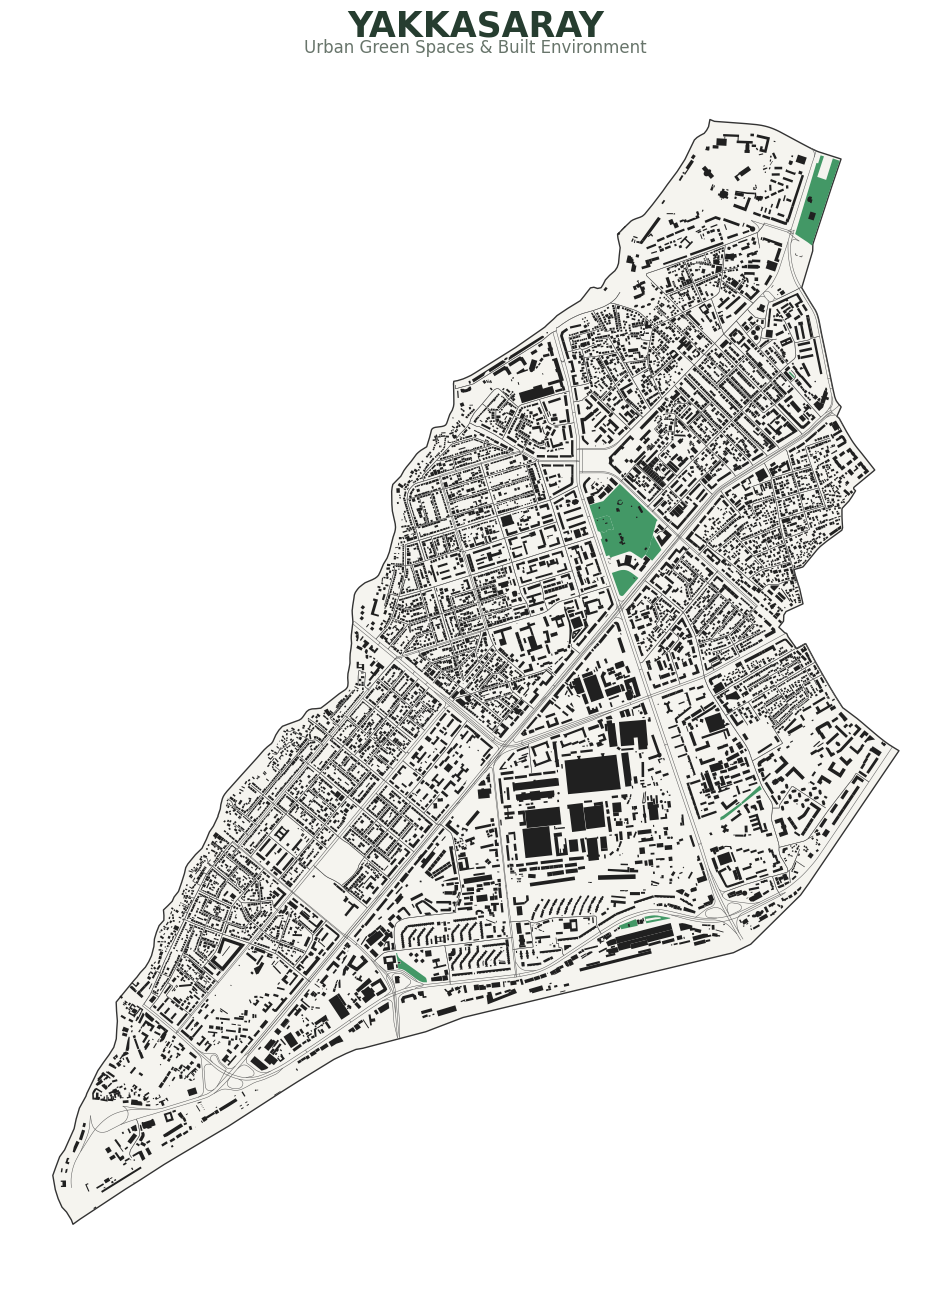

In [20]:
fig, ax = plt.subplots(figsize=(13, 13))

# District background
district_clip.plot(
    ax=ax,
    color="#F5F4EF",
    edgecolor="#333333",
    linewidth=1.0,
    zorder=1
)

# Green spaces
parks_clip.plot(
    ax=ax,
    color="#39935F",
    edgecolor="none",
    alpha=0.95,
    zorder=2
)

# Road network
roads_clip.plot(
    ax=ax,
    color="#555555",
    linewidth=0.35,
    zorder=3
)

# Building footprints
buildings_clip.plot(
    ax=ax,
    color="#202020",
    edgecolor="none",
    zorder=4
)

# Title
ax.set_title(
    "YAKKASARAY",
    fontsize=25,
    fontweight="bold",
    color="#263D30",
    pad=20
)

ax.text(
    0.5, 1.01,
    "Urban Green Spaces & Built Environment",
    transform=ax.transAxes,
    ha="center",
    fontsize=12,
    color="#68756B"
)

ax.set_axis_off()
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

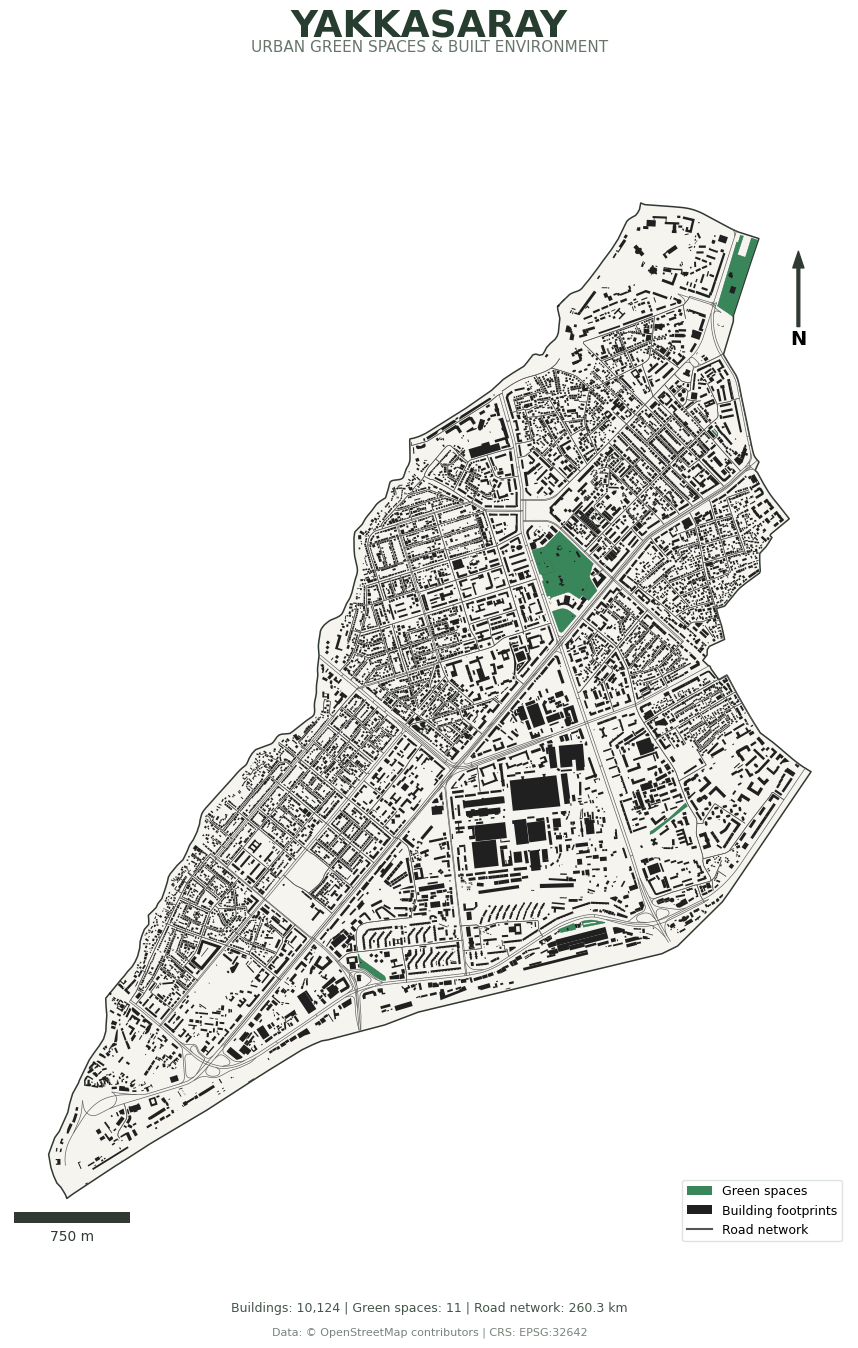

In [21]:
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Calculate basic statistics
building_count = len(buildings_clip)
park_count = len(parks_clip)
road_km = roads_clip.geometry.length.sum() / 1000

# Create figure
fig, ax = plt.subplots(figsize=(12, 14), facecolor="white")

# District background
district_clip.plot(
    ax=ax,
    color="#F5F4EF",
    edgecolor="#303A32",
    linewidth=1.1,
    zorder=1
)

# Green spaces
parks_clip.plot(
    ax=ax,
    color="#39865A",
    edgecolor="#286B47",
    linewidth=0.3,
    zorder=2
)

# Roads
roads_clip.plot(
    ax=ax,
    color="#555555",
    linewidth=0.45,
    zorder=3
)

# Buildings
buildings_clip.plot(
    ax=ax,
    color="#202020",
    edgecolor="none",
    zorder=4
)

# Title
fig.suptitle(
    "YAKKASARAY",
    fontsize=27,
    fontweight="bold",
    color="#263D30",
    y=0.965
)

fig.text(
    0.5, 0.935,
    "URBAN GREEN SPACES & BUILT ENVIRONMENT",
    ha="center",
    fontsize=11,
    color="#68756B"
)

# Legend
legend_elements = [
    Patch(facecolor="#39865A", label="Green spaces"),
    Patch(facecolor="#202020", label="Building footprints"),
    Line2D([0], [0], color="#555555",
           linewidth=1.5, label="Road network")
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#D5DCD5",
    fontsize=9
)

# Scale bar
ax.add_artist(
    ScaleBar(
        1,
        units="m",
        dimension="si-length",
        location="lower left",
        box_alpha=0,
        color="#303A32",
        length_fraction=0.15
    )
)

# North arrow
ax.annotate(
    "N",
    xy=(0.94, 0.91),
    xytext=(0.94, 0.83),
    xycoords="axes fraction",
    ha="center",
    va="center",
    fontsize=14,
    fontweight="bold",
    arrowprops=dict(
        facecolor="#303A32",
        edgecolor="#303A32",
        width=2,
        headwidth=8
    )
)

# Remove axes
ax.set_axis_off()
ax.set_aspect("equal")

# Footer
fig.text(
    0.5, 0.035,
    f"Buildings: {building_count:,} | "
    f"Green spaces: {park_count:,} | "
    f"Road network: {road_km:.1f} km",
    ha="center",
    fontsize=9,
    color="#44564A"
)

fig.text(
    0.5, 0.018,
    "Data: © OpenStreetMap contributors | CRS: EPSG:32642",
    ha="center",
    fontsize=8,
    color="#78847B"
)

plt.tight_layout(rect=[0.03, 0.07, 0.97, 0.91])

plt.savefig(
    "Day_07_Yakkasaray_Urban_Map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [23]:
# Expanded green-space categories
green_tags = {
    "leisure": [
        "park",
        "garden",
        "nature_reserve",
        "common"
    ],

    "landuse": [
        "recreation_ground",
        "grass",
        "meadow",
        "forest",
        "allotments",
        "orchard"
    ],

    "natural": [
        "wood",
        "grassland",
        "scrub",
        "heath"
    ]
}

# Download expanded green spaces
parks = ox.features_from_polygon(
    polygon,
    tags=green_tags
)

# Keep polygon geometries
parks = parks[
    parks.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

# Reproject
parks = parks.to_crs(epsg=32642)

# Clip to Yakkasaray
parks_clip = gpd.clip(
    parks,
    district_clip
)

print("Expanded green-space features:", len(parks_clip))

Expanded green-space features: 447


In [24]:
print(
    parks_clip["leisure"].value_counts(
        dropna=True
    )
)

print(
    parks_clip["landuse"].value_counts(
        dropna=True
    )
)

print(
    parks_clip["natural"].value_counts(
        dropna=True
    )
)

leisure
park      10
garden     1
Name: count, dtype: int64
landuse
grass     242
forest      1
Name: count, dtype: int64
natural
wood         170
scrub         18
grassland      9
Name: count, dtype: int64


In [25]:
print("Total green-space features:", len(parks_clip))

print("Geometry types:")
print(parks_clip.geom_type.value_counts())

Total green-space features: 447
Geometry types:
Polygon    447
Name: count, dtype: int64


In [26]:
green_count = len(parks_clip)

print("Mapped green-space polygons:", green_count)

Mapped green-space polygons: 447


In [27]:
parks_clip.plot(
    ax=ax,
    color="#39865A",
    edgecolor="none",
    alpha=0.95,
    zorder=2
)

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

In [28]:
green_count = len(parks_clip)

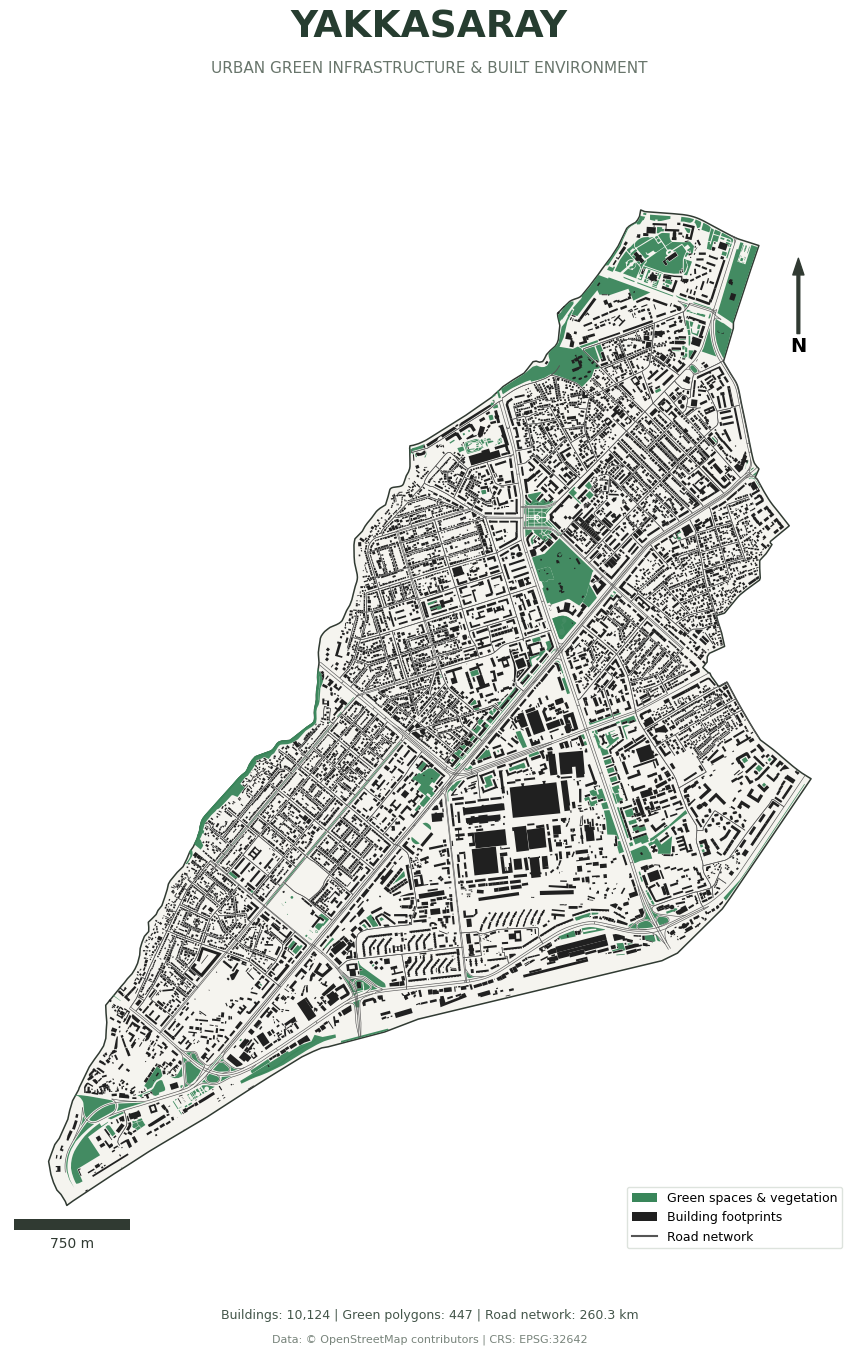

In [30]:
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Statistics
building_count = len(buildings_clip)
green_count = len(parks_clip)
road_km = roads_clip.geometry.length.sum() / 1000

# Create a fresh figure
fig, ax = plt.subplots(figsize=(12, 14), facecolor="white")

# District boundary
district_clip.plot(
    ax=ax, color="#F5F4EF",
    edgecolor="#303A32", linewidth=1.1, zorder=1
)

# Expanded green spaces
parks_clip.plot(
    ax=ax, color="#39865A",
    edgecolor="none", alpha=0.95, zorder=2
)

# Roads
roads_clip.plot(
    ax=ax, color="#555555",
    linewidth=0.45, zorder=3
)

# Building footprints
buildings_clip.plot(
    ax=ax, color="#202020",
    edgecolor="none", zorder=4
)

# Title
fig.suptitle(
    "YAKKASARAY",
    fontsize=27, fontweight="bold",
    color="#263D30", y=0.97
)

fig.text(
    0.5, 0.925,
    "URBAN GREEN INFRASTRUCTURE & BUILT ENVIRONMENT",
    ha="center", fontsize=11, color="#68756B"
)

# Legend
legend_elements = [
    Patch(facecolor="#39865A", label="Green spaces & vegetation"),
    Patch(facecolor="#202020", label="Building footprints"),
    Line2D([0], [0], color="#555555",
           linewidth=1.5, label="Road network")
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#D5DCD5",
    fontsize=9
)

# Scale bar
ax.add_artist(
    ScaleBar(
        1, units="m",
        dimension="si-length",
        location="lower left",
        box_alpha=0,
        color="#303A32",
        length_fraction=0.15
    )
)

# North arrow
ax.annotate(
    "N",
    xy=(0.94, 0.91),
    xytext=(0.94, 0.83),
    xycoords="axes fraction",
    ha="center", va="center",
    fontsize=14, fontweight="bold",
    arrowprops=dict(
        facecolor="#303A32",
        edgecolor="#303A32",
        width=2,
        headwidth=8
    )
)

ax.set_axis_off()
ax.set_aspect("equal")

# Footer statistics
fig.text(
    0.5, 0.035,
    f"Buildings: {building_count:,} | "
    f"Green polygons: {green_count:,} | "
    f"Road network: {road_km:.1f} km",
    ha="center", fontsize=9, color="#44564A"
)

fig.text(
    0.5, 0.018,
    "Data: © OpenStreetMap contributors | CRS: EPSG:32642",
    ha="center", fontsize=8, color="#78847B"
)

plt.tight_layout(rect=[0.03, 0.07, 0.97, 0.91])

plt.savefig(
    "Day_07_Yakkasaray_Urban_Map.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()